In [20]:
import pandas as pd
import numpy as np


import matplotlib.pyplot as plt

import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import missingno as msno
from plotly.subplots import make_subplots

In [11]:
# import data
df_train = pd.read_csv("data/Train.csv")
sample_submission = pd.read_csv("data/SampleSubmission.csv")

df_train.head(5)

,Place_ID X Date,Date,Place_ID,target,target_min,target_max,target_variance,target_count,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,...,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
0,010Q650 X 2020-01-02,2020-01-02,010Q650,38.0,23.0,53.0,769.50,92,11.000000,60.200001,...,38.593017,-61.752587,22.363665,1793.793579,3227.855469,0.010579,74.481049,37.501499,-62.142639,22.545118
1,010Q650 X 2020-01-03,2020-01-03,010Q650,39.0,25.0,63.0,1319.85,91,14.600000,48.799999,...,59.624912,-67.693509,28.614804,1789.960449,3384.226562,0.015104,75.630043,55.657486,-53.868134,19.293652
2,010Q650 X 2020-01-04,2020-01-04,010Q650,24.0,8.0,56.0,1181.96,96,16.400000,33.400002,...,49.839714,-78.342701,34.296977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,010Q650 X 2020-01-05,2020-01-05,010Q650,49.0,10.0,55.0,1113.67,96,6.911948,21.300001,...,29.181258,-73.896588,30.545446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,010Q650 X 2020-01-06,2020-01-06,010Q650,21.0,9.0,52.0,1164.82,95,13.900001,44.700001,...,0.797294,-68.612480,26.899694,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 30557 entries, 0 to 30556
Data columns (total 82 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   Place_ID X Date                                      30557 non-null  str    
 1   Date                                                 30557 non-null  str    
 2   Place_ID                                             30557 non-null  str    
 3   target                                               30557 non-null  float64
 4   target_min                                           30557 non-null  float64
 5   target_max                                           30557 non-null  float64
 6   target_variance                                      30557 non-null  float64
 7   target_count                                         30557 non-null  int64  
 8   precipitable_water_entire_atmosphere                 30557 non-null  float64


In [14]:
df_train.describe()

,target,target_min,target_max,target_variance,target_count,precipitable_water_entire_atmosphere,relative_humidity_2m_above_ground,specific_humidity_2m_above_ground,temperature_2m_above_ground,u_component_of_wind_10m_above_ground,...,L3_SO2_sensor_zenith_angle,L3_SO2_solar_azimuth_angle,L3_SO2_solar_zenith_angle,L3_CH4_CH4_column_volume_mixing_ratio_dry_air,L3_CH4_aerosol_height,L3_CH4_aerosol_optical_depth,L3_CH4_sensor_azimuth_angle,L3_CH4_sensor_zenith_angle,L3_CH4_solar_azimuth_angle,L3_CH4_solar_zenith_angle
count,30557.000000,30557.000000,30557.000000,3.055700e+04,30557.000000,30557.000000,30557.000000,30557.000000,30557.000000,30557.000000,...,23320.000000,23320.000000,23320.000000,5792.000000,5792.000000,5792.000000,5792.000000,5792.000000,5792.000000,5792.000000
mean,61.148045,29.025866,117.992234,7.983756e+03,125.831135,15.302326,70.552747,0.006004,9.321342,0.416886,...,35.590916,-123.697777,46.533951,923.231949,1711.793613,0.016227,1.254703,13.849040,-69.098594,23.100630
std,46.861309,33.119775,100.417713,4.863090e+04,146.581856,10.688573,18.807884,0.003787,9.343226,2.707990,...,18.955228,71.916036,14.594267,929.633988,1741.299304,0.027016,55.101250,18.004375,84.702355,24.786350
min,1.000000,1.000000,1.000000,0.000000e+00,2.000000,0.420044,5.128572,0.000139,-34.647879,-15.559646,...,0.000000,-179.880630,0.000000,0.000000,0.000000,0.000000,-105.367363,0.000000,-179.947422,0.000000
25%,25.000000,5.000000,60.000000,1.064920e+03,44.000000,7.666667,58.600002,0.003403,3.123071,-1.097864,...,19.451524,-165.882624,36.693094,0.000000,0.000000,0.000000,0.000000,0.000000,-161.726937,0.000000
50%,50.000000,15.000000,91.000000,2.395350e+03,72.000000,12.200000,74.099998,0.004912,8.478424,0.222092,...,37.918838,-156.637162,47.445010,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,80.000000,44.000000,155.000000,5.882550e+03,150.000000,19.900000,85.450001,0.007562,16.201563,1.772925,...,52.270055,-118.453598,57.438181,1861.674119,3393.541633,0.023829,62.245728,27.412303,0.000000,47.090635
max,815.000000,438.000000,999.000000,1.841490e+06,1552.000000,72.599998,100.000000,0.021615,37.437921,17.955124,...,66.111289,179.776125,79.631711,2112.522949,6478.550544,0.210483,77.355232,59.972710,179.813344,69.992363


In [6]:
sample_submission.head(5)

,Place_ID X Date,target
0,0OS9LVX X 2020-01-02,0
1,0OS9LVX X 2020-01-03,0
2,0OS9LVX X 2020-01-04,0
3,0OS9LVX X 2020-01-05,0
4,0OS9LVX X 2020-01-06,0


In [7]:
sample_submission.info()

<class 'pandas.DataFrame'>
RangeIndex: 16136 entries, 0 to 16135
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Place_ID X Date  16136 non-null  str  
 1   target           16136 non-null  int64
dtypes: int64(1), str(1)
memory usage: 252.3 KB


In [27]:
# Anzahl NaNs pro Spalte (nur Spalten mit NaNs, absteigend sortiert)
nan_counts = df_train.isna().sum()
nan_counts = nan_counts[nan_counts > 0].sort_values(ascending=False)
print(f"Number of missing values in each column:\n{nan_counts}")

# Als Prozent der Zeilen
nan_percent = (df_train.isna().sum() / len(df_train) * 100).round(2)
nan_percent = nan_percent[nan_percent > 0].sort_values(ascending=False)
print(f"Percentage of missing values in each column:\n{nan_percent}")



Number of missing values in each column:
L3_CH4_solar_zenith_angle                        24765
L3_CH4_sensor_zenith_angle                       24765
L3_CH4_sensor_azimuth_angle                      24765
L3_CH4_aerosol_height                            24765
L3_CH4_CH4_column_volume_mixing_ratio_dry_air    24765
                                                 ...  
L3_AER_AI_solar_azimuth_angle                      197
L3_AER_AI_sensor_altitude                          197
L3_AER_AI_absorbing_aerosol_index                  197
L3_AER_AI_sensor_zenith_angle                      197
L3_AER_AI_sensor_azimuth_angle                     197
Length: 68, dtype: int64
Percentage of missing values in each column:
L3_CH4_solar_zenith_angle                        81.05
L3_CH4_sensor_zenith_angle                       81.05
L3_CH4_sensor_azimuth_angle                      81.05
L3_CH4_aerosol_height                            81.05
L3_CH4_CH4_column_volume_mixing_ratio_dry_air    81.05
         

<Axes: >

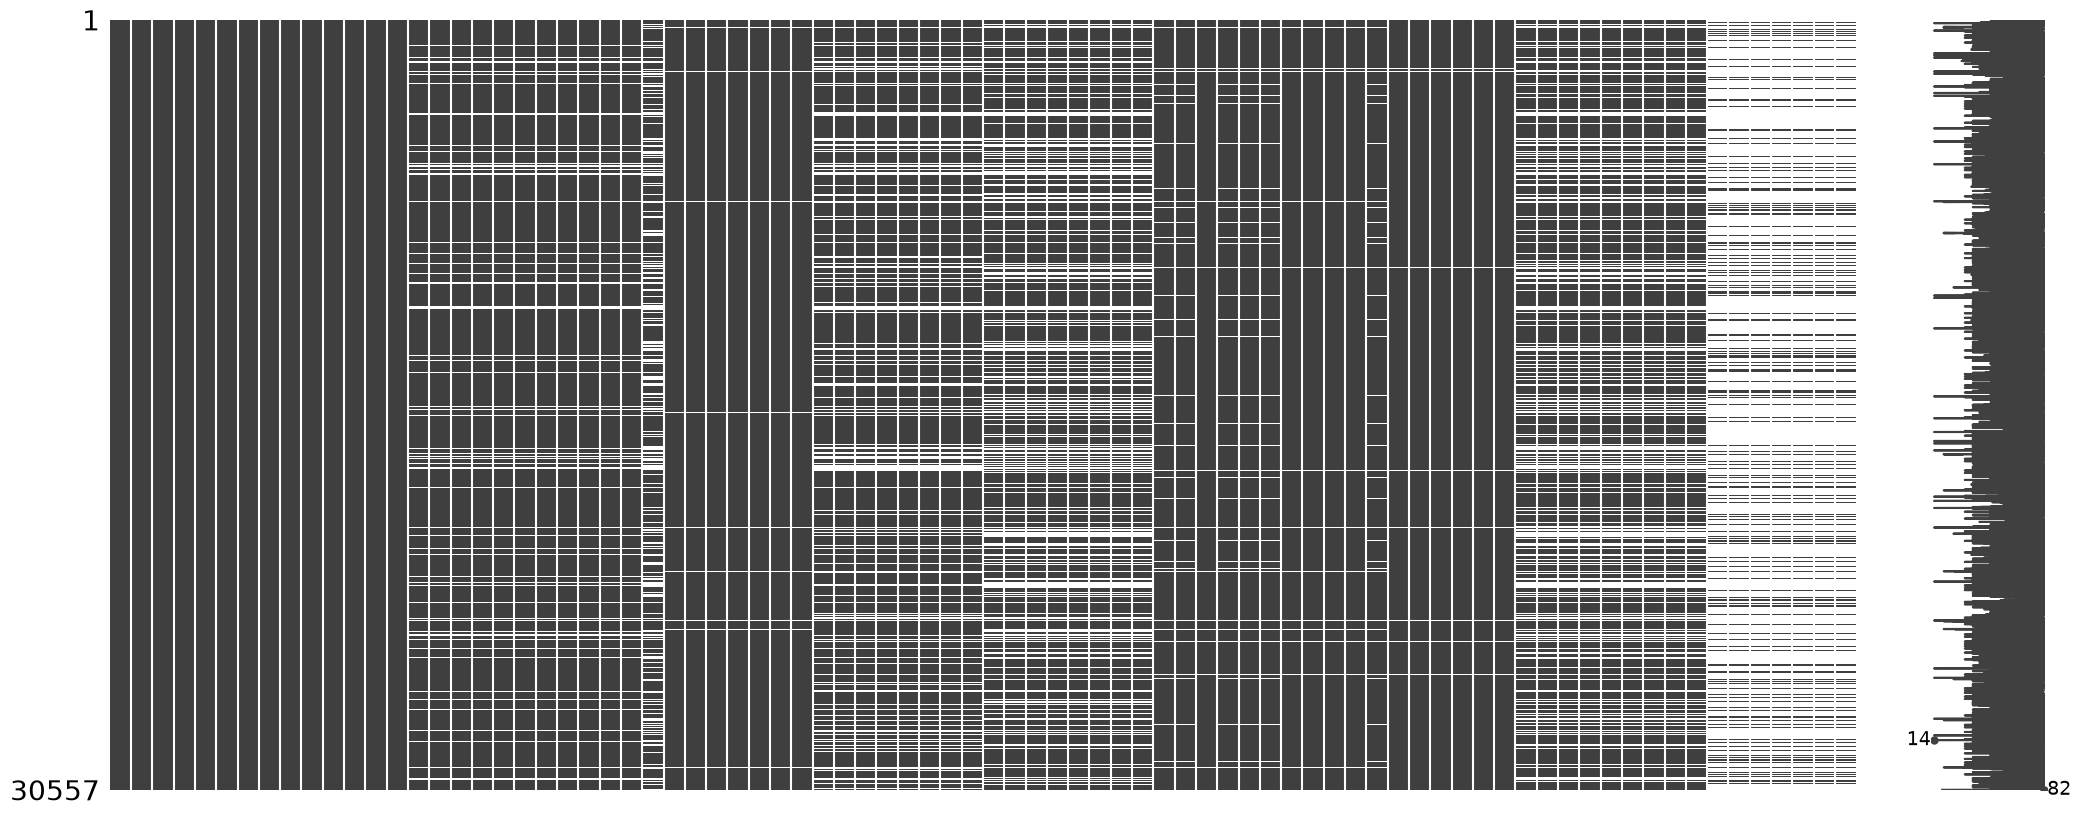

In [21]:
msno.matrix(df_train)


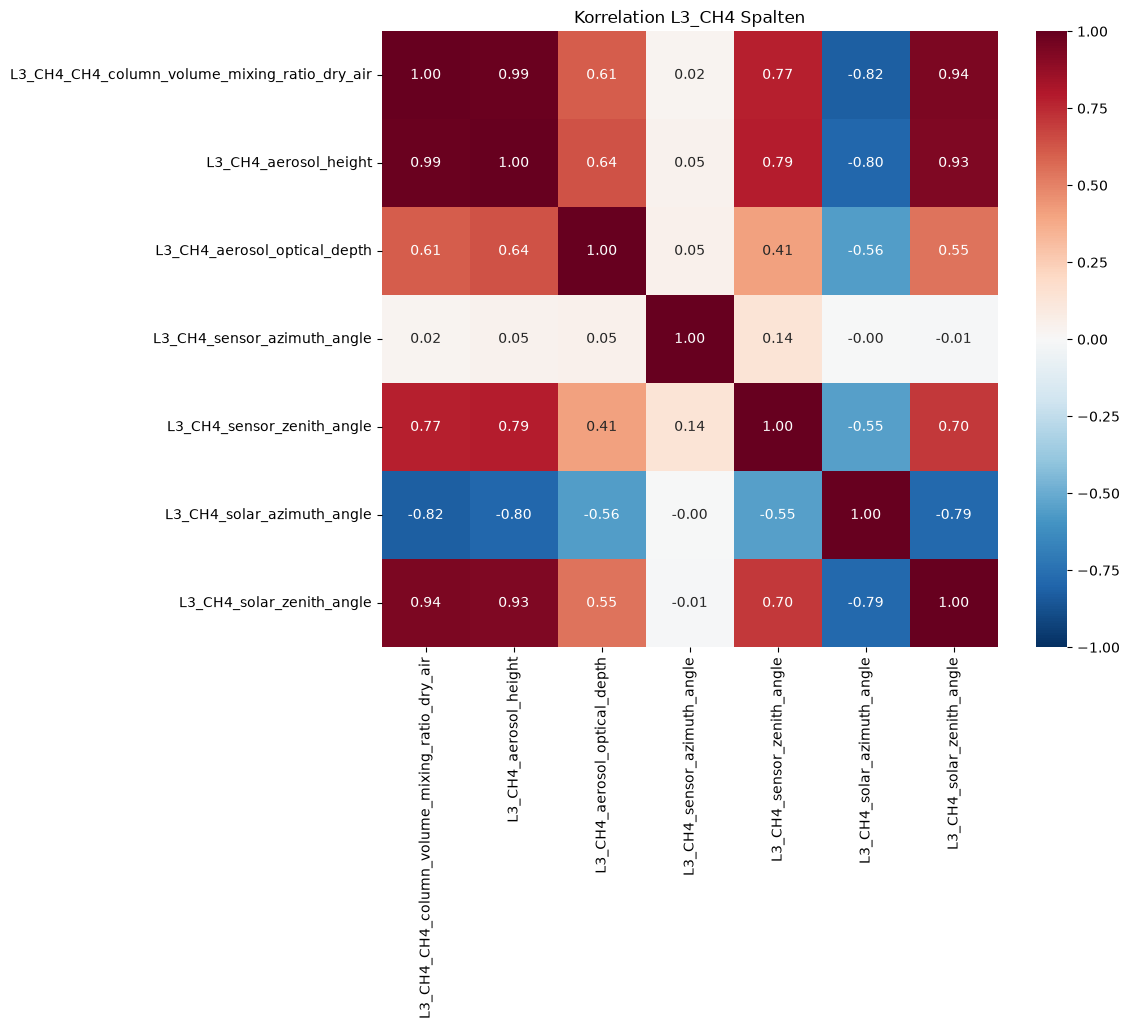

In [38]:
# z.B. alle Spalten einer Gruppe auswählen (hier per Namensmuster)
namensmuster = "L3_CH4"
cols = [c for c in df_train.columns if c.startswith(namensmuster)]
corr = df_train[cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    cmap="RdBu_r",   # divergierend, neutraler Mittelpunkt bei 0
    center=0,
    vmin=-1, vmax=1,
    annot=True, fmt=".2f",
    square=True
)
plt.title(f"Korrelation {namensmuster} Spalten")
plt.show()


In [34]:
# Ausgabe von Korrelationsmatrix mit Treshold, um nur stark korrelierte Paare anzuzeigen
def top_correlated_pairs(df, threshold=0.9):
    corr = df.select_dtypes(include=np.number).corr().abs()
    mask = np.triu(np.ones(corr.shape), k=1).astype(bool)
    pairs = corr.where(mask).stack().sort_values(ascending=False)
    return pairs[pairs > threshold]

top_correlated_pairs(df_train, threshold=0.9)

L3_CLOUD_solar_zenith_angle   L3_AER_AI_solar_zenith_angle      0.999833
L3_HCHO_solar_zenith_angle    L3_SO2_solar_zenith_angle         0.999675
L3_CO_solar_zenith_angle      L3_HCHO_solar_zenith_angle        0.997472
                              L3_SO2_solar_zenith_angle         0.997280
L3_CLOUD_sensor_zenith_angle  L3_AER_AI_sensor_zenith_angle     0.996903
                                                                  ...   
L3_CO_sensor_azimuth_angle    L3_HCHO_sensor_azimuth_angle      0.926295
L3_NO2_sensor_azimuth_angle   L3_HCHO_sensor_azimuth_angle      0.923449
L3_CO_sensor_azimuth_angle    L3_AER_AI_sensor_azimuth_angle    0.923437
L3_NO2_sensor_azimuth_angle   L3_CO_sensor_azimuth_angle        0.909320
L3_O3_cloud_fraction          L3_SO2_cloud_fraction             0.906168
Length: 68, dtype: float64

In [42]:
# Anzahl der eindeutigen Namensgruppen in den Spaltennamen
prefixe = df_train.columns.str[0:8].unique()
print(f"Number of unique name groups in column names: {prefixe}")

Number of unique name groups in column names: Index(['Place_ID', 'Date', 'target', 'target_m', 'target_v', 'target_c',
       'precipit', 'relative', 'specific', 'temperat', 'u_compon', 'v_compon',
       'L3_NO2_N', 'L3_NO2_a', 'L3_NO2_c', 'L3_NO2_s', 'L3_NO2_t', 'L3_O3_O3',
       'L3_O3_cl', 'L3_O3_se', 'L3_O3_so', 'L3_CO_CO', 'L3_CO_H2', 'L3_CO_cl',
       'L3_CO_se', 'L3_CO_so', 'L3_HCHO_', 'L3_CLOUD', 'L3_AER_A', 'L3_SO2_S',
       'L3_SO2_a', 'L3_SO2_c', 'L3_SO2_s', 'L3_CH4_C', 'L3_CH4_a', 'L3_CH4_s'],
      dtype='str')


# Übersicht der Sentinel-5P (L3) Satellitenspalten

Die Spalten mit dem Präfix `L3_` repräsentieren wissenschaftlich aufbereitete, gerasterte (Level 3) Daten des TROPOMI-Spektrometers. Da der Satellit die Atmosphäre spektroskopisch von oben durchleuchtet, basieren die Werte auf der Absorption von Sonnenlicht innerhalb einer hypothetischen Luftsäule über dem Zielort.

### 1. Konzentrationsmaße (Teilchendichten)
* **`..._column_number_density`**: Vertikal integrierte Gesamtdichte. Gibt die Stoffmenge der Gasmoleküle pro Flächeneinheit ($\text{mol}/\text{m}^2$) in der gesamten Luftsäule vom Boden bis zur Weltraumgrenze an.
* **`..._tropospheric_column_number_density`**: Integrierte Teilchendichte beschränkt auf die Troposphäre (unterste Atmosphärenschicht, ca. 0–12 km). Chemisch am relevantesten für anthropogene Bodenemissionen.
* **`..._stratospheric_column_number_density`**: Integrierte Teilchendichte innerhalb der Stratosphäre (darüberliegende Schicht, primär relevant für die globale Ozon-Bilanz).
* **`..._slant_column_number_density`**: Die "schräge" Teilchendichte entlang des tatsächlichen optischen Lichtwegs (Sonne $\rightarrow$ Erdboden $\rightarrow$ Satellitensensor). Dieser physikalische Rohwert bildet die Basis für die Berechnung der vertikalen Dichten.

### 2. Optische & Atmosphärische Korrekturfaktoren
* **`..._amf_total` / `..._amf_tropospheric` (Air Mass Factor)**: Optischer Skalierungsfaktor zur Umrechnung von schräger zu vertikaler Dichte ($AMF = \text{slant} / \text{vertical}$). Korrigiert Einflüsse durch Rayleigh-/Mie-Streuung sowie die Bodenalbedo (Reflektivität des Untergrunds).
* **`..._absorbing_aerosol_index` (bei `AER_AI`)**: Dimensionsloser Index der UV-Rückstreuung. Positive Werte indizieren UV-absorbierende Schwebeteilchen (z. B. Ruß, Staub, Asche); negative Werte stehen für rein streuende Partikel (Sulfate, Wassertropfen).

### 3. Messgeometrie & Winkel (Optischer Aufbau)
* **`..._sensor_zenith_angle`**: Einfallswinkel des Satellitenblicks relativ zur Senkrechten (Zenit) des Messortes. $0^\circ$ bedeutet eine Messung exakt im Nadir (senkrecht von oben).
* **`..._solar_zenith_angle`**: Einfallswinkel der Sonnenstrahlen relativ zum Zenit (Sonnenstand am Himmel).
* **`..._sensor_azimuth_angle` / `..._solar_azimuth_angle`**: Horizontaler Kompasswinkel (gemessen ab Nord im Uhrzeigersinn) für die Position des Satellitensensors bzw. der Sonne.

### 4. Wolkeninterferenz
* **`..._cloud_fraction`**: Der wolkenbedeckte Anteil des Messpixels ($0$ bis $1$). Da Wolken die Sicht auf bodennahe Schichten blockieren, beeinflusst dieser Parameter die Signalqualität und die Berechnungen der troposphärischen Dichten massiv.


In [44]:

# prefixes = sorted(df_train.columns.str[:8].unique())
# l3_prefixes = [p for p in prefixes if p.startswith("L3_")]

# for prefix in l3_prefixes:
#     cols = [c for c in df_train.columns if c.startswith(prefix)]
#     if len(cols) < 2:
#         continue  # Korrelation braucht mind. 2 Spalten

#     corr = df_train[cols].corr()

#     plt.figure(figsize=(8, 6))
#     sns.heatmap(
#         corr,
#         cmap="RdBu_r",
#         center=0,
#         vmin=-1, vmax=1,
#         annot=True, fmt=".2f",
#         square=True
#     )
#     plt.title(f"Korrelation: {prefix}")
#     plt.tight_layout()
#     plt.show()


# Übersicht der Meteorologischen Wetterspalten

Diese Spalten enthalten physikalische Boden- und Atmosphärenmesswerte. Sie beschreiben die thermodynamischen und dynamischen Bedingungen der unteren Troposphäre, welche maßgeblich beeinflussen, wie stark Schadstoffe am Boden konzentriert, transportiert oder verdünnt werden.

### 1. Thermodynamik & Luftfeuchtigkeit
* **`temperature_2m_above_ground`**: Die Lufttemperatur gemessen in der Standardhöhe von 2 Metern über dem Boden (in Kelvin oder Celsius). Beeinflusst chemische Reaktionsgeschwindigkeiten und vertikale Luftbewegungen.
* **`specific_humidity_2m_above_ground`**: Spezifische Luftfeuchtigkeit ($g$ Wasserdampf pro $kg$ feuchte Luft) auf 2 Metern Höhe. Beschreibt den absoluten Wasserdampfgehalt, welcher für photochemische Reaktionen und Partikelwachstum (Hygroskopie) wichtig ist.
* **`relative_humidity_2m_above_ground`**: Relative Luftfeuchtigkeit in % auf 2 Metern Höhe. Zeigt das Verhältnis des aktuellen Wasserdampfdrucks zum Sättigungsdampfdruck. Hohe Werte begünstigen das Zusammenklumpen von Partikeln.

### 2. Winddynamik (Vektorkomponenten)
* **`u_component_of_wind_10m_above_ground`**: Die zonale Windkomponente (Ost-West-Richtung) in 10 Metern Höhe über dem Boden. Ein positiver Wert bedeutet Wind aus Westen (Westwind), ein negativer Wert Wind aus Osten.
* **`v_component_of_wind_10m_above_ground`**: Die meridionale Windkomponente (Nord-Süd-Richtung) in 10 Metern Höhe über dem Boden. Ein positiver Wert bedeutet Wind aus Süden (Südwind), ein negativer Wert Wind aus Norden.
* *Hinweis zur Physik:* Aus diesen beiden rechtwinkligen Vektoren lässt sich die absolute Windgeschwindigkeit ($\sqrt{u^2 + v^2}$) sowie die Windrichtung ($\arctan2(v, u)$) mathematisch ableiten.

### 3. Globalstrahlung & Energiebilanz
* **`thermal_radiation_flux`**: Thermischer Strahlungsfluss (Infrarot-/Langwellenstrahlung) an der Oberfläche. Spiegelt die Wärmeabstrahlung des Bodens oder der Wolkenobergrenze wider (wichtig für nächtliche Inversionswetterlagen).
* **`precipitable_water`**: Das gesamte ausfällbare Wasser in der Luftsäule. Gibt die hypothetische Höhe einer Wasserschicht (in $mm$ oder $\text{kg}/\text{m}^2$) an, die entstehen würde, wenn der gesamte Wasserdampf der Säule vollständig kondensieren und abregnen würde. Ein Indikator für großskalige Feuchtigkeit und potenzielle Wolkenbildung.


In [45]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 16136 entries, 0 to 16135
Data columns (total 77 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   Place_ID X Date                                      16136 non-null  str    
 1   Date                                                 16136 non-null  str    
 2   Place_ID                                             16136 non-null  str    
 3   precipitable_water_entire_atmosphere                 16136 non-null  float64
 4   relative_humidity_2m_above_ground                    16136 non-null  float64
 5   specific_humidity_2m_above_ground                    16136 non-null  float64
 6   temperature_2m_above_ground                          16136 non-null  float64
 7   u_component_of_wind_10m_above_ground                 16136 non-null  float64
 8   v_component_of_wind_10m_above_ground                 16136 non-null  float64


In [48]:
# datumsspalte in datetime konvertieren
df_test['Date'] = pd.to_datetime(df_test['Date'])


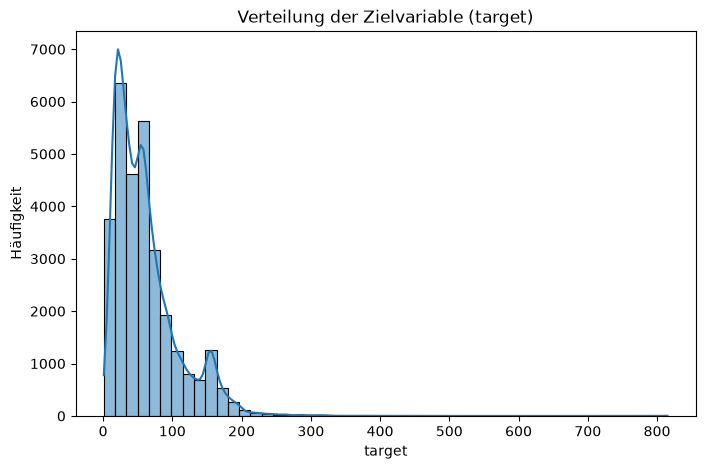

In [49]:
# target PM 2.5 plotten
plt.figure(figsize=(8, 5))
sns.histplot(df_train["target"], bins=50, kde=True)
plt.title("Verteilung der Zielvariable (target)")
plt.xlabel("target")
plt.ylabel("Häufigkeit")
plt.show()

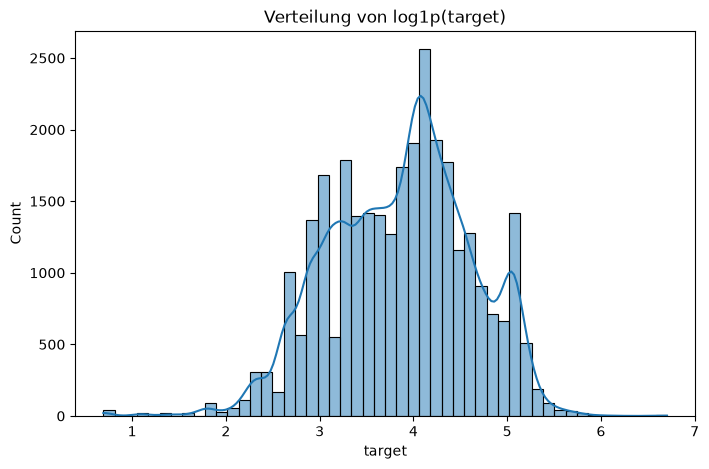

In [ ]:
# target logaritmiert plotten
plt.figure(figsize=(8, 5))
sns.histplot(np.log1p(df_train["target"]), bins=50, kde=True)
plt.title("Verteilung von log1p(target)")
plt.show()

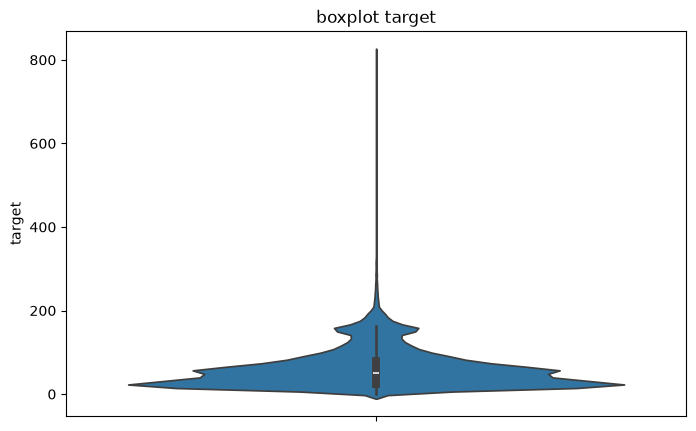

In [56]:
plt.figure(figsize=(8, 5))
sns.violinplot(df_train["target"])
plt.title("boxplot target")
plt.show()

In [57]:
# Einzelne stätte
df_train["Place_ID"].nunique()

340

In [58]:
# Prüfen ob NaNs mit Orten korrelieren. 
# Anzahl NaNs pro Zeile (über alle Spalten)
df_train["n_missing"] = df_train.isna().sum(axis=1)

# Durchschnittliche Anzahl NaNs pro Ort
nan_by_place = df_train.groupby("Place_ID")["n_missing"].mean().sort_values(ascending=False)
nan_by_place


Place_ID
7DRFQCK    35.178571
5IUK9TG    29.333333
0GBXTHY    28.808511
0PP73FZ    26.457447
92A8XLV    26.215054
             ...    
6HXPCBH     4.670455
WP7PTYQ     4.659574
1X421B8     4.391892
UB4SRN5     4.053191
YDW4K0H     3.954545
Name: n_missing, Length: 340, dtype: float64

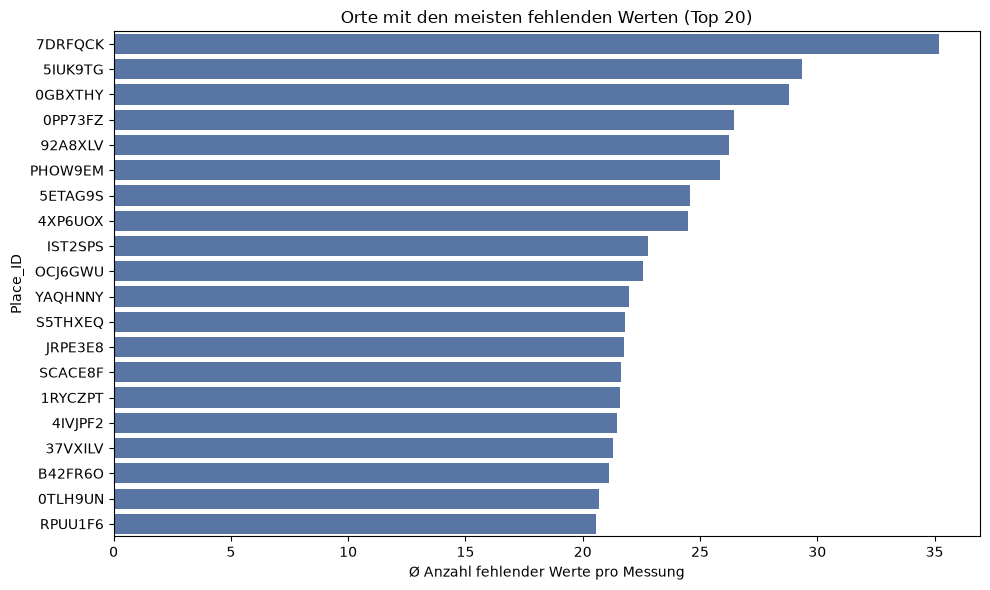

In [60]:
top20 = nan_by_place.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=top20.values, y=top20.index, color="#4C72B0", order=top20.index)
plt.xlabel("Ø Anzahl fehlender Werte pro Messung")
plt.ylabel("Place_ID")
plt.title("Orte mit den meisten fehlenden Werten (Top 20)")
plt.tight_layout()
plt.show()

In [61]:
# Berechnen, wie groß der Anteil der NaNs durch Ort erklärt wird
overall_mean = df_train["n_missing"].mean()
group_means = df_train.groupby("Place_ID")["n_missing"].mean()
group_sizes = df_train.groupby("Place_ID")["n_missing"].size()

ss_between = (group_sizes * (group_means - overall_mean) ** 2).sum()
ss_total = ((df_train["n_missing"] - overall_mean) ** 2).sum()

eta_squared = ss_between / ss_total
print(f"Anteil der Varianz, der durch Place_ID erklärt wird: {eta_squared:.2%}")


Anteil der Varianz, der durch Place_ID erklärt wird: 14.02%


#Die 14% rechtfertigen ortsabhängige Imputation + ein Missing-Indicator-Feature, aber keine pauschale Entfernung von Orten oder Zeilen.

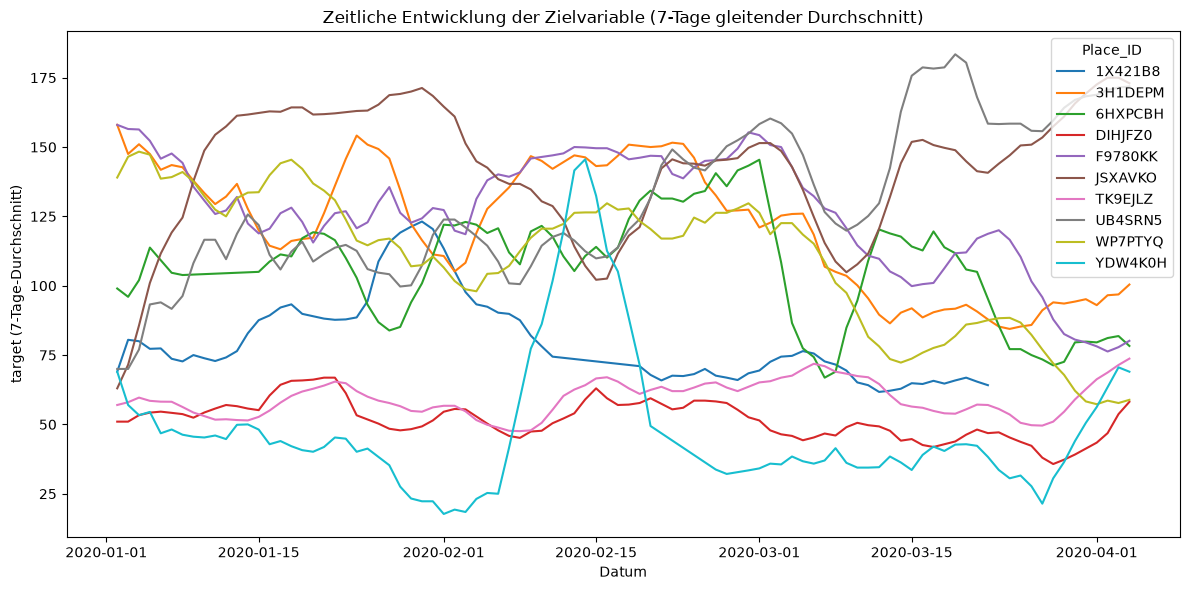

In [66]:
# Orte mit den wenigsten NaNs ermitteln (wie vorher berechnet)
nan_by_place = df_train.groupby("Place_ID")["n_missing"].mean().sort_values()
top5_places = nan_by_place.head(10).index.tolist()

df_top5 = df_train[df_train["Place_ID"].isin(top5_places)].copy()
df_top5["Date"] = pd.to_datetime(df_top5["Date"])  # ggf. Spaltennamen anpassen
df_top5 = df_top5.sort_values(["Place_ID", "Date"])

# 7-Tage gleitender Durchschnitt pro Ort, um Tagesrauschen zu glätten
df_top5["target_rolling"] = (
    df_top5.groupby("Place_ID")["target"]
    .transform(lambda s: s.rolling(window=7, min_periods=1).mean())
)

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_top5, x="Date", y="target_rolling", hue="Place_ID", palette="tab10")
plt.title("Zeitliche Entwicklung der Zielvariable (7-Tage gleitender Durchschnitt)")
plt.xlabel("Datum")
plt.ylabel("target (7-Tage-Durchschnitt)")
plt.legend(title="Place_ID")
plt.tight_layout()
plt.show()


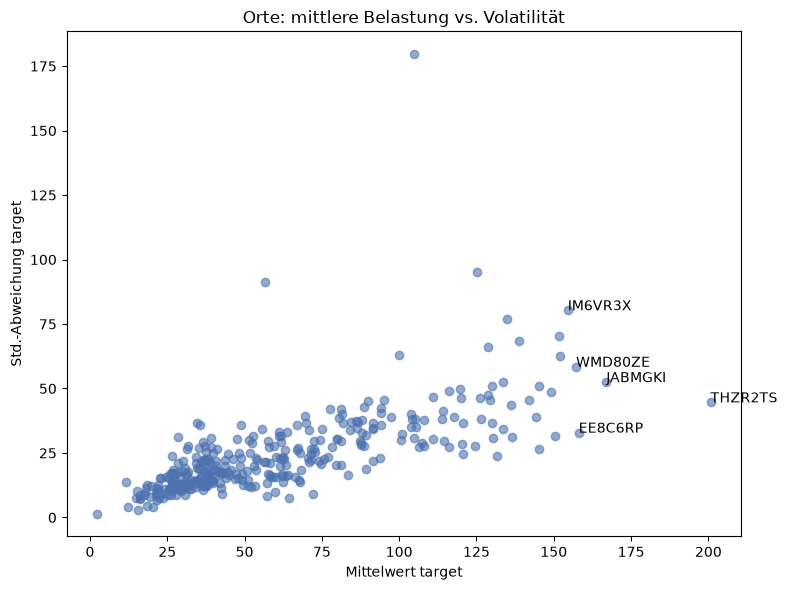

In [67]:
# Bestimmung von Hotspots (Orte mit konstant hoher Belastung)
place_stats = (
    df_train.groupby("Place_ID")["target"]
    .agg(["mean", "var", "std", "count"])
    .sort_values("mean", ascending=False)
)
place_stats

plt.figure(figsize=(8, 6))
plt.scatter(place_stats["mean"], place_stats["std"], alpha=0.6, color="#4C72B0")
plt.xlabel("Mittelwert target")
plt.ylabel("Std.-Abweichung target")
plt.title("Orte: mittlere Belastung vs. Volatilität")

# die auffälligsten Orte beschriften
top_outliers = place_stats.head(5)
for place_id, row in top_outliers.iterrows():
    plt.annotate(place_id, (row["mean"], row["std"]))

plt.tight_layout()
plt.show()


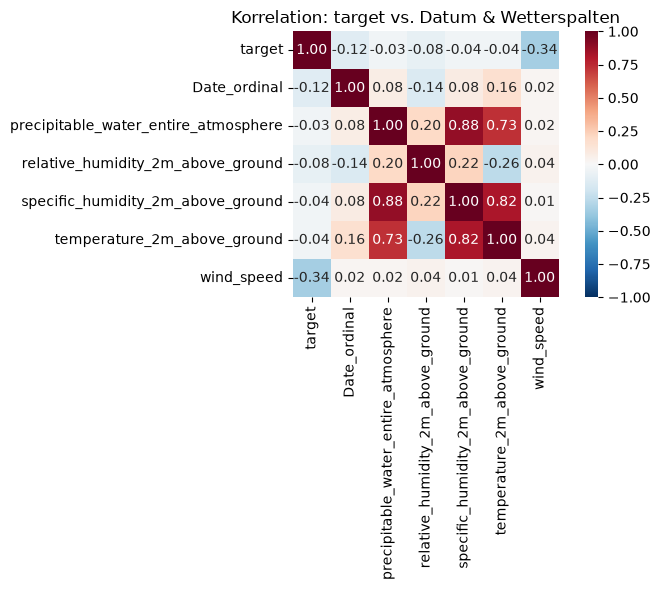

In [69]:
# Korrelation zwischen Wetterdaten und target 
# Absolute Windgeschwindigkeit berechnen
df_train["wind_speed"] = np.sqrt(
    df_train["u_component_of_wind_10m_above_ground"]**2
    + df_train["v_component_of_wind_10m_above_ground"]**2
)

# Datum in numerischen Wert umwandeln (für Pearson-Korrelation nötig)
df_train["Date"] = pd.to_datetime(df_train["Date"])
df_train["Date_ordinal"] = df_train["Date"].map(pd.Timestamp.toordinal)

cols = [
    "target",
    "Date_ordinal",
    "precipitable_water_entire_atmosphere",
    "relative_humidity_2m_above_ground",
    "specific_humidity_2m_above_ground",
    "temperature_2m_above_ground",
    "wind_speed",
]

corr = df_train[cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    cmap="RdBu_r",
    center=0,
    vmin=-1, vmax=1,
    annot=True, fmt=".2f",
    square=True
)
plt.title("Korrelation: target vs. Datum & Wetterspalten")
plt.tight_layout()
plt.show()


## Erkenntnisse: Korrelation target vs. Datum & Wetterspalten (für spätere Transformation)

- **`wind_speed` (`sqrt(u²+v²)`) ist mit Abstand das stärkste lineare Feature** (r = -0.34 zu `target`) → unbedingt als Feature behalten. Negativer Zusammenhang ist physikalisch plausibel (Wind verdünnt/verwirbelt Schadstoffe).
- Alle anderen geprüften Features korrelieren nur schwach linear mit `target` (|r| ≤ 0.12): `Date_ordinal` (-0.12), `relative_humidity` (-0.08), `specific_humidity`/`temperature` (je -0.04), `precipitable_water` (-0.03). Schwache lineare Korrelation ≠ Irrelevanz – nichtlineare Zusammenhänge sind möglich (z.B. über Tree-based Modelle abbildbar), also nicht vorschnell droppen.
- **Starke Multikollinearität zwischen den Wetterspalten selbst** (nicht mit target):
  - `precipitable_water_entire_atmosphere` ↔ `specific_humidity_2m_above_ground`: 0.88
  - `specific_humidity_2m_above_ground` ↔ `temperature_2m_above_ground`: 0.82
  - `precipitable_water_entire_atmosphere` ↔ `temperature_2m_above_ground`: 0.73
  → Redundanz reduzieren: für lineare Modelle ggf. nur eine Spalte behalten oder per PCA zusammenfassen.
- `Date_ordinal` (linearer Zeitindex) ist vermutlich die falsche Kodierung für die Zeitkomponente, da der im Lineplot erkannte Zusammenhang eher **saisonal** ist (Peak Ende Feb/Anfang März, siehe Rolling-Average-Plot) statt linear steigend/fallend → bei der Transformation stattdessen zyklische/saisonale Zeit-Features prüfen (z.B. Monat, Tag im Jahr, ggf. sin/cos-Encoding).

### To-Do beim Feature Engineering
- [ ] `wind_speed` als Feature aufnehmen
- [ ] Redundanz bei Feuchte-/Temperaturspalten reduzieren (Auswahl oder PCA)
- [ ] Zeitkomponente saisonal statt linear kodieren
- [ ] Ortsabhängige Imputation + Missing-Indicator-Feature (siehe Eta² = 14% weiter oben)
- [ ] Stark korrelierte `L3_`-Winkel-Spalten (Threshold > 0.9) reduzieren (siehe `top_correlated_pairs`)


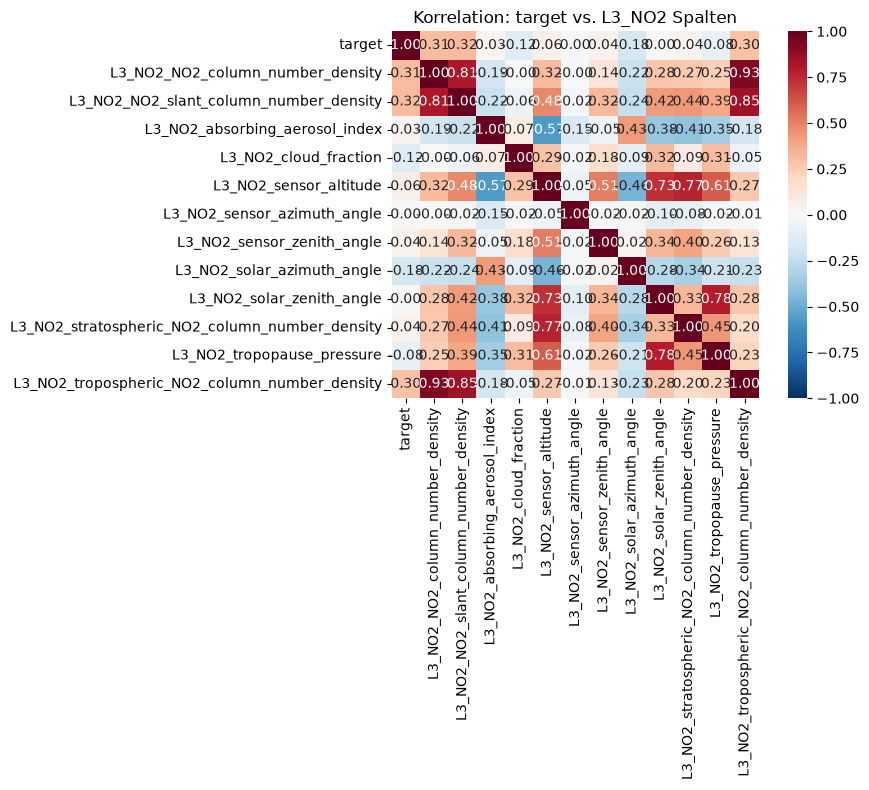


L3_NO2: Korrelation der Spalten mit target (sortiert)
L3_NO2_NO2_slant_column_number_density            0.315718
L3_NO2_NO2_column_number_density                  0.306772
L3_NO2_tropospheric_NO2_column_number_density     0.295380
L3_NO2_solar_azimuth_angle                       -0.177861
L3_NO2_cloud_fraction                            -0.123956
L3_NO2_tropopause_pressure                       -0.084550
L3_NO2_sensor_altitude                            0.057273
L3_NO2_sensor_zenith_angle                        0.037475
L3_NO2_stratospheric_NO2_column_number_density    0.035819
L3_NO2_absorbing_aerosol_index                    0.030386
L3_NO2_sensor_azimuth_angle                       0.003722
L3_NO2_solar_zenith_angle                         0.001192
Name: target, dtype: float64


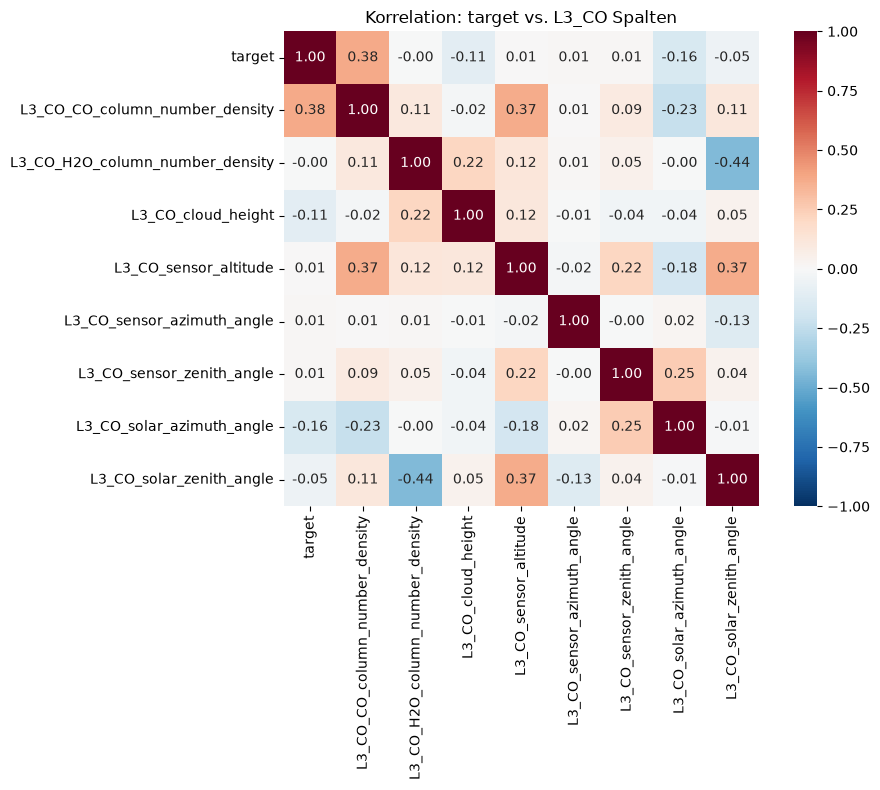


L3_CO: Korrelation der Spalten mit target (sortiert)
L3_CO_CO_column_number_density     0.375737
L3_CO_solar_azimuth_angle         -0.159954
L3_CO_cloud_height                -0.106133
L3_CO_solar_zenith_angle          -0.049490
L3_CO_sensor_zenith_angle          0.011007
L3_CO_sensor_azimuth_angle         0.009023
L3_CO_sensor_altitude              0.006389
L3_CO_H2O_column_number_density   -0.000596
Name: target, dtype: float64


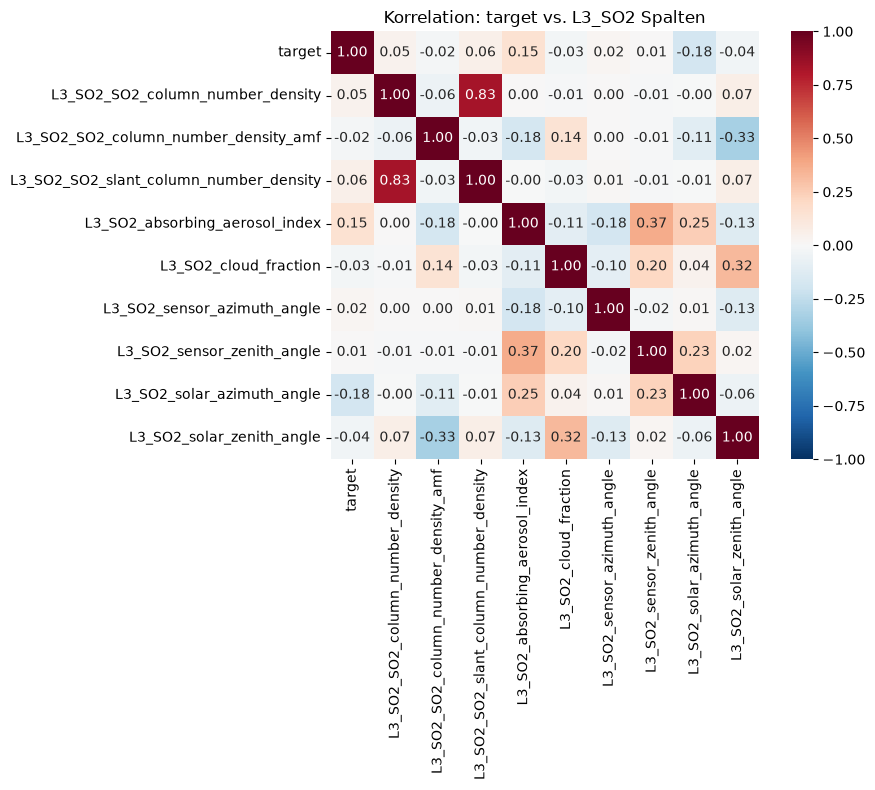


L3_SO2: Korrelation der Spalten mit target (sortiert)
L3_SO2_solar_azimuth_angle               -0.180241
L3_SO2_absorbing_aerosol_index            0.152000
L3_SO2_SO2_slant_column_number_density    0.059665
L3_SO2_SO2_column_number_density          0.045052
L3_SO2_solar_zenith_angle                -0.037803
L3_SO2_cloud_fraction                    -0.025099
L3_SO2_sensor_azimuth_angle               0.016728
L3_SO2_SO2_column_number_density_amf     -0.016116
L3_SO2_sensor_zenith_angle                0.007332
Name: target, dtype: float64


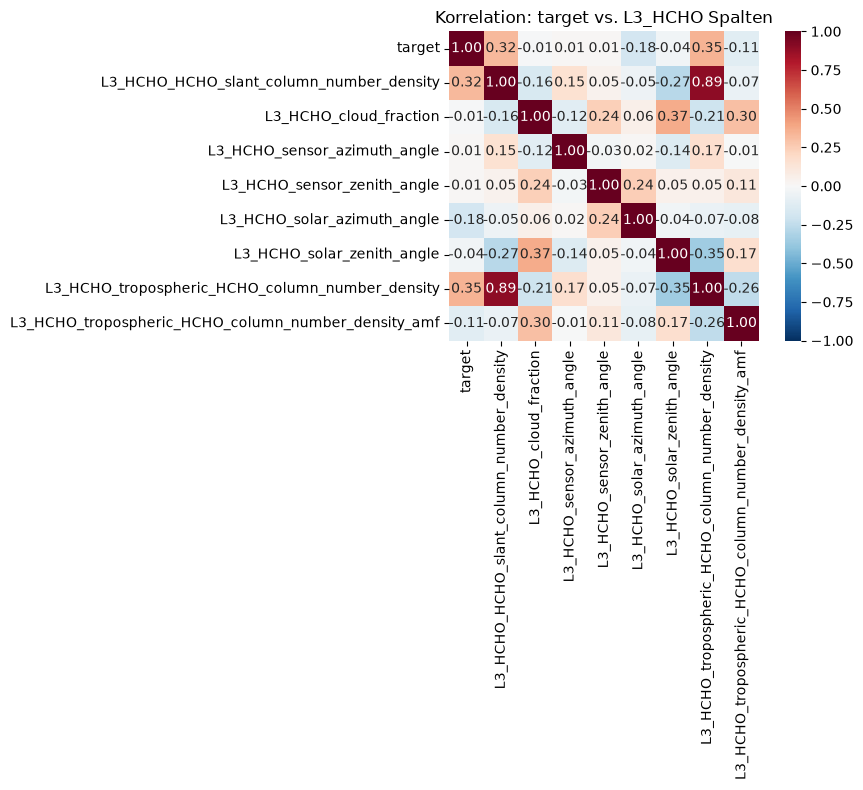


L3_HCHO: Korrelation der Spalten mit target (sortiert)
L3_HCHO_tropospheric_HCHO_column_number_density        0.347125
L3_HCHO_HCHO_slant_column_number_density               0.320849
L3_HCHO_solar_azimuth_angle                           -0.181548
L3_HCHO_tropospheric_HCHO_column_number_density_amf   -0.114348
L3_HCHO_solar_zenith_angle                            -0.038851
L3_HCHO_sensor_azimuth_angle                           0.013455
L3_HCHO_cloud_fraction                                -0.011736
L3_HCHO_sensor_zenith_angle                            0.008498
Name: target, dtype: float64


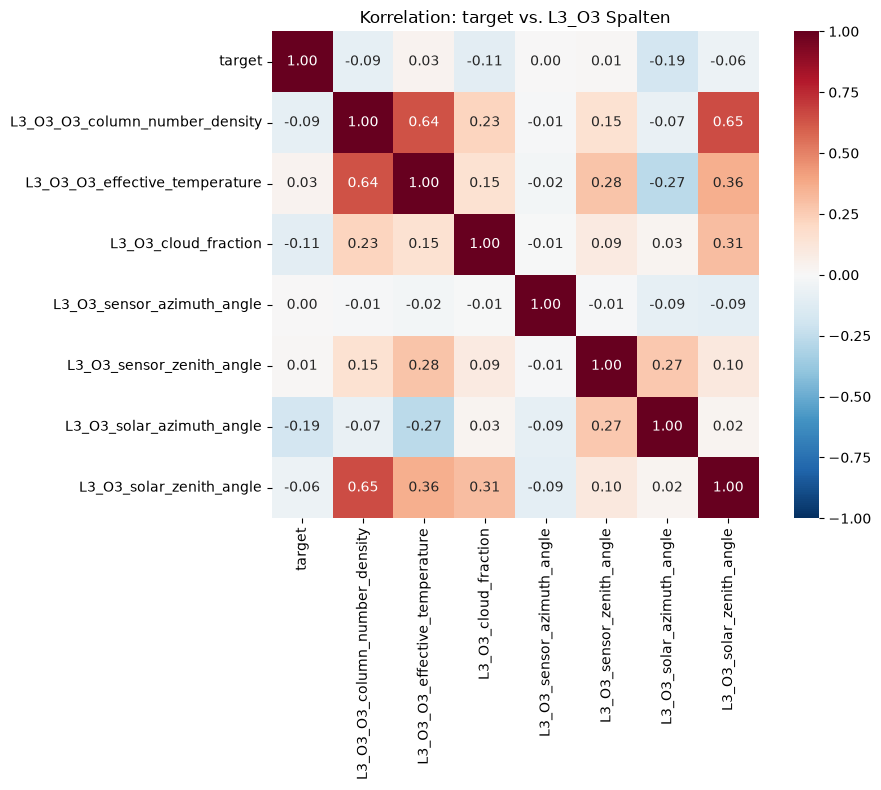


L3_O3: Korrelation der Spalten mit target (sortiert)
L3_O3_solar_azimuth_angle        -0.185363
L3_O3_cloud_fraction             -0.108538
L3_O3_O3_column_number_density   -0.088099
L3_O3_solar_zenith_angle         -0.055617
L3_O3_O3_effective_temperature    0.034375
L3_O3_sensor_zenith_angle         0.012354
L3_O3_sensor_azimuth_angle        0.001783
Name: target, dtype: float64


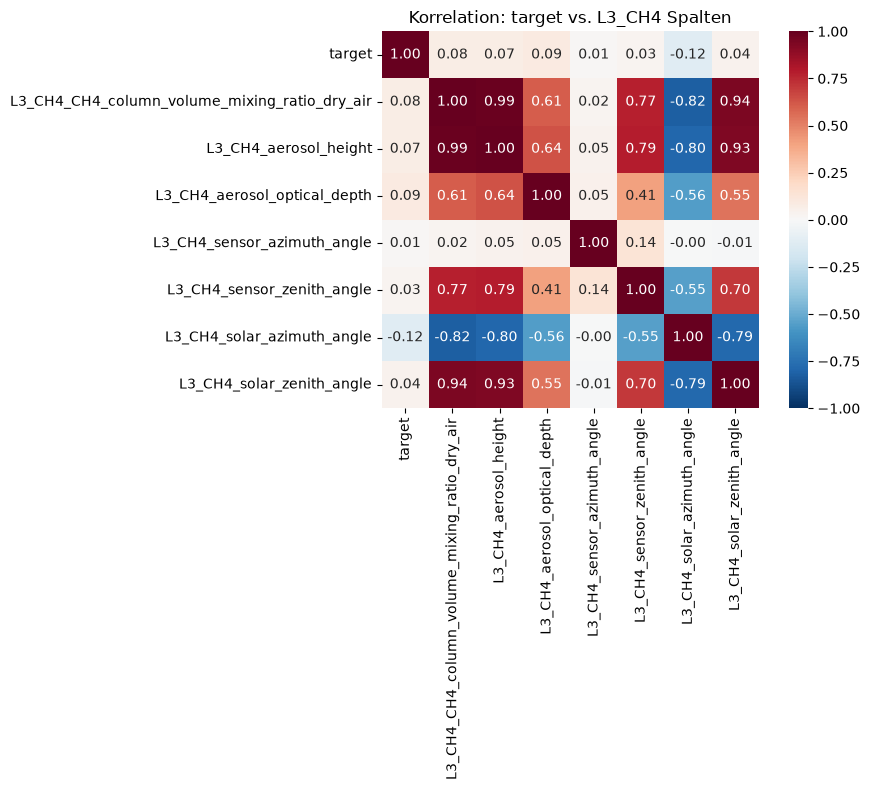


L3_CH4: Korrelation der Spalten mit target (sortiert)
L3_CH4_solar_azimuth_angle                      -0.118004
L3_CH4_aerosol_optical_depth                     0.086445
L3_CH4_CH4_column_volume_mixing_ratio_dry_air    0.075086
L3_CH4_aerosol_height                            0.073632
L3_CH4_solar_zenith_angle                        0.043264
L3_CH4_sensor_zenith_angle                       0.031025
L3_CH4_sensor_azimuth_angle                      0.012264
Name: target, dtype: float64


In [73]:
# Korrelationsmatrix (inkl. target) für jede Schadstoffgruppe
gas_groups = ["L3_NO2", "L3_CO", "L3_SO2", "L3_HCHO", "L3_O3", "L3_CH4"]

for gas in gas_groups:
    cols = [c for c in df_train.columns if c.startswith(gas)]
    cols = ["target"] + cols

    corr = df_train[cols].corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr,
        cmap="RdBu_r",
        center=0,
        vmin=-1, vmax=1,
        annot=True, fmt=".2f",
        square=True
    )
    plt.title(f"Korrelation: target vs. {gas} Spalten")
    plt.tight_layout()
    plt.show()

    # Zusätzlich: Korrelation der Gruppenspalten mit target, sortiert
    print(f"\n{gas}: Korrelation der Spalten mit target (sortiert)")
    print(corr["target"].drop("target").sort_values(key=abs, ascending=False))


Korrelation cloud_fraction-Spalten mit n_missing (sortiert):
L3_CLOUD_cloud_fraction    0.718935
L3_O3_cloud_fraction       0.696201
L3_NO2_cloud_fraction      0.559059
L3_SO2_cloud_fraction      0.338573
L3_HCHO_cloud_fraction     0.323614
Name: n_missing, dtype: float64


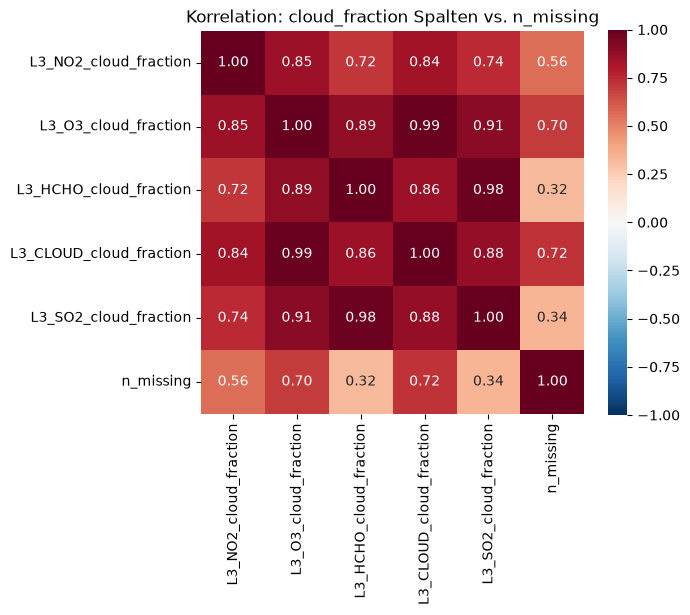

In [74]:
# Prüfen, ob cloud_fraction mit der Anzahl fehlender Werte zusammenhängt
# (Hypothese: mehr Wolken -> mehr Satelliten-Messausfälle)
cloud_cols = [c for c in df_train.columns if "cloud_fraction" in c]

corr_cloud_nan = (
    df_train[cloud_cols + ["n_missing"]]
    .corr()["n_missing"]
    .drop("n_missing")
    .sort_values(key=abs, ascending=False)
)
print("Korrelation cloud_fraction-Spalten mit n_missing (sortiert):")
print(corr_cloud_nan)

plt.figure(figsize=(7, 6))
sns.heatmap(
    df_train[cloud_cols + ["n_missing"]].corr(),
    cmap="RdBu_r",
    center=0,
    vmin=-1, vmax=1,
    annot=True, fmt=".2f",
    square=True
)
plt.title("Korrelation: cloud_fraction Spalten vs. n_missing")
plt.tight_layout()
plt.show()


## Erkenntnisse: Schadstoffgruppen vs. target & cloud_fraction vs. Missingness (für spätere Transformation)

### 1. Korrelation Schadstoffe vs. target
- **`L3_CO_CO_column_number_density` (r = 0.376), `L3_HCHO_tropospheric_HCHO_column_number_density` (r = 0.347) und `L3_NO2_NO2_(slant_)column_number_density` (r ≈ 0.30–0.32) sind die bisher stärksten Einzelprädiktoren** im gesamten Datensatz – stärker als `wind_speed` (-0.34). Physikalisch plausibel: CO und NO2 sind klassische Verbrennungs-Tracer (Verkehr, Biomasse-Verbrennung), die oft gemeinsam mit Feinstaub auftreten.
- SO2-, O3- und CH4-Dichtespalten korrelieren nur schwach mit `target` (|r| ≤ 0.15). CH4 zusätzlich mit Vorsicht behandeln, da nur ~19% der Zeilen nicht-NaN sind.
- **`..._solar_azimuth_angle` zeigt in fast jeder Gruppe eine moderate Korrelation (-0.12 bis -0.19)** – vermutlich kein eigenständiger physikalischer Treiber, sondern ein Artefakt der Satelliten-Überflugsgeometrie, das mit Datum/Jahreszeit konfundiert ist. Nicht blind als Haupt-Feature nutzen.

### 2. cloud_fraction vs. Missingness
- Die Hypothese "mehr Wolken → mehr Sensor-Ausfälle" ist klar bestätigt: `L3_CLOUD_cloud_fraction` (r = 0.72) und `L3_O3_cloud_fraction` (r = 0.70) korrelieren stark mit `n_missing`, `L3_NO2_cloud_fraction` (0.56), `L3_SO2_cloud_fraction`/`L3_HCHO_cloud_fraction` (~0.32–0.34) etwas schwächer.
- Wichtig: Die Ausfälle verschiedener Gase hängen über eine **gemeinsame Ursache** (schlechte Sicht an bewölkten Tagen) zusammen, treten also nicht unabhängig pro Gas auf.

### To-Do beim Feature Engineering (Ergänzung)
- [ ] `L3_CO_CO_column_number_density`, `L3_HCHO_tropospheric_HCHO_column_number_density`, `L3_NO2_NO2_(slant_)column_number_density` als Kern-Features priorisieren
- [ ] SO2/O3/CH4-Dichtespalten nachrangig behandeln, CH4 wegen hoher Missingness besonders vorsichtig
- [ ] `solar_azimuth_angle`-Spalten nicht direkt als Haupttreiber nutzen, stattdessen saisonale Zeit-Features (Monat/Tag im Jahr) bevorzugen
- [ ] Imputation modellbasiert statt rein ortsbasiert durchführen (z.B. IterativeImputer/KNN-Imputer mit Wetter-/Cloud-Features), da Missingness über eine gemeinsame Ursache (Wolken) gruppenübergreifend zusammenhängt
- [ ] Ein gemeinsames "Sichtbarkeits"-Feature (z.B. `L3_CLOUD_cloud_fraction`) als Proxy für generelle Datenverfügbarkeit ergänzend zum Missing-Indicator einführen


## Gesamt-Checkliste Feature Engineering (konsolidiert aus der gesamten EDA)

### Zielvariable (target)
- [ ] `target` ist rechtsschief verteilt → `log1p`-Transformation prüfen (siehe Histogramm/Violinplot)

### Fehlende Werte / Imputation
- [ ] Imputation modellbasiert + ortsabhängig durchführen (z.B. IterativeImputer/KNN-Imputer mit Wetter-/Cloud-Features), nicht nur per-Place-Mittelwert/Median
- [ ] Missing-Indicator-Feature(s) ergänzen (Missingness ist informativ, kein MCAR)
- [ ] Gemeinsames "Sichtbarkeits"-Feature ergänzen (z.B. `L3_CLOUD_cloud_fraction`), da Ausfälle gruppenübergreifend durch Wolken verursacht werden
- [ ] Keine pauschale Entfernung von Orten/Zeilen mit hoher Fehlquote (würde Daten Richtung "wolkenfreie" Orte verzerren)

### Zeit-/Saisonfeatures
- [ ] Zeitkomponente saisonal statt linear kodieren (Monat/Tag im Jahr, ggf. sin/cos-Encoding) statt `Date_ordinal`
- [ ] `..._solar_azimuth_angle`-Spalten nicht direkt als Haupttreiber nutzen – vermutlich Datum/Saison-Artefakt (Überflugsgeometrie)

### Feature-Auswahl & Redundanzreduktion
- [ ] `wind_speed` (`sqrt(u²+v²)`) als Feature aufnehmen (stärkstes Wetter-Feature, r = -0.34)
- [ ] Redundanz bei Feuchte-/Temperaturspalten reduzieren (precipitable_water/specific_humidity/temperature stark korreliert, 0.73–0.88) – Auswahl oder PCA
- [ ] Stark korrelierte `L3_`-Winkel-Spalten (Threshold > 0.9, v.a. Sensor-/Solar-Zenith/Azimuth über Gruppen hinweg) reduzieren
- [ ] `L3_CO_CO_column_number_density`, `L3_HCHO_tropospheric_HCHO_column_number_density`, `L3_NO2_NO2_(slant_)column_number_density` priorisieren – stärkste bisher gefundene Einzelprädiktoren (r = 0.30–0.38)
- [ ] SO2-/O3-/CH4-Dichtespalten nachrangig behandeln; CH4 zusätzlich vorsichtig wegen 81% Missingness


## Ergänzung: Warum Winkel-Spalten so stark korrelieren (Satelliten-Geometrie & Air Mass Factor)

- Sentinel-5P/TROPOMI misst bei einem Überflug **alle Gase gleichzeitig** → Sensor-/Sonnenwinkel (`sensor_zenith_angle`, `sensor_azimuth_angle`, `solar_zenith_angle`, `solar_azimuth_angle`) hängen nur von Ort/Datum/Uhrzeit des Überflugs ab, nicht vom jeweiligen Gas. Deshalb sind z.B. `L3_CLOUD_solar_zenith_angle` und `L3_AER_AI_solar_zenith_angle` praktisch identisch (r = 0.9998) – es ist derselbe physikalische Winkel, nur pro Gas-Produkt dupliziert, nicht 7 unabhängige Informationen.
- `..._slant_column_number_density` (Rohmessung entlang des schrägen Lichtwegs, winkelabhängig) vs. `..._column_number_density` (vertikal, winkelkorrigiert): größerer Winkel → längerer optischer Weg durch die Atmosphäre → automatisch höhere Rohmessung. Der **Air Mass Factor (AMF)** korrigiert das: `vertikale Dichte = schräge Dichte / AMF`, mit `AMF ≈ 1/cos(sensor_zenith) + 1/cos(solar_zenith)` (vereinfacht).

### Ergebnis des empirischen Tests ("implizites AMF" = slant / vertical)

- **Hypothese "Satellit fliegt meist senkrecht über der Position, AMF ≈ 1" ist widerlegt.** Das implizite AMF liegt bei keinem der drei testbaren Gase nahe 1 und ist auch nicht annähernd konstant: NO2 Median ≈ 1.97 (Std 0.58), SO2 Median ≈ 0.34 (Std 0.30), HCHO Median ≈ 0.55 (Std 1.34). Die AMF-Korrektur bewirkt also real etwas.
- **NO2 bestätigt die einfache Geometrie-Erklärung:** implizites AMF korreliert moderat positiv mit `sensor_zenith_angle` (r = 0.29) – größerer Winkel → größeres AMF, wie physikalisch erwartet (sichtbar im Scatterplot: untere Begrenzung der Punktwolke steigt mit dem Winkel).
- **SO2 validiert die Methode gegen das offizielle AMF** (Korrelation implizit vs. offiziell: r = 0.745, ähnliche Mittelwerte 0.40 vs. 0.43) – aber die Korrelation mit `solar_zenith_angle` ist **negativ** (r = -0.36), entgegen der naiven Geometrie-Erwartung. D.h. das offizielle AMF hängt bei schwachen Absorbern wie SO2 nicht nur von der reinen Blickgeometrie ab, sondern stark von Aerosolen, Wolken, Bodenalbedo und Mehrfachstreuung.
- **HCHO ist als Test unzuverlässig:** nur schwache Übereinstimmung zwischen implizitem und offiziellem AMF (r = 0.21) und ein systematischer Mittelwert-Unterschied (0.60 vs. 1.06) – vermutlich weil `slant` (Gesamtsäule) und `tropospheric_vertical` nicht exakt dieselbe Säule referenzieren. Dem Rohquotienten hier nicht trauen.

### Fazit & Konsequenz für Feature Engineering
Die AMF-Korrektur ist kein triviales Artefakt eines meist senkrechten Überflugs, sondern wirkt spürbar und unterschiedlich stark je nach Gas (bei NO2 überwiegend geometrisch erklärbar, bei SO2 zusätzlich von Strahlungstransport-Effekten geprägt). **Praktische Konsequenz:** keine eigene AMF-Näherung für die Modellierung bauen – stattdessen die bereits bereitgestellten korrigierten `vertical`-Spalten und (wo vorhanden) die offiziellen `_amf`-Spalten nutzen. Winkel-Spalten weiterhin nur als redundante Geometrie-Diagnostik behandeln (siehe Redundanzreduktion in der Checkliste oben).

- [x] Empirischer Test durchgeführt: implizites AMF (slant/vertical) berechnet und mit Winkeln sowie (wo vorhanden) offiziellem AMF verglichen – Ergebnis siehe oben.



=== NO2 ===
Ausreisser ausserhalb 1.-99. Perzentil: 516 von 25757 (2.0%)
Implizites AMF (robust): mean=1.987, median=1.966, std=0.575
Korrelation mit implizitem AMF (robuste Teilmenge):
sensor_zenith_angle    0.293604
solar_zenith_angle     0.114340
Name: implied_amf, dtype: float64


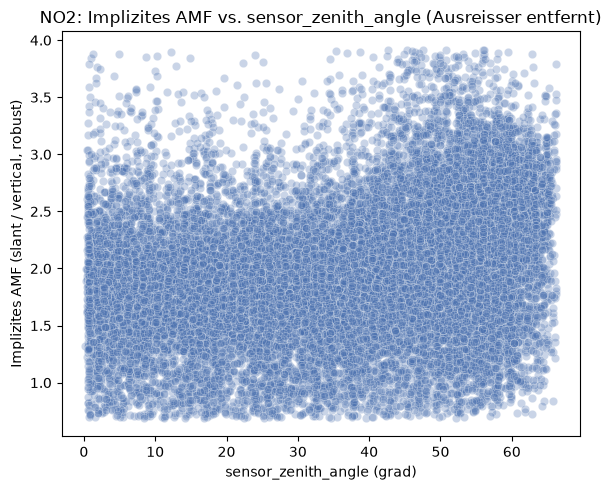


=== HCHO ===
Ausreisser ausserhalb 1.-99. Perzentil: 458 von 22802 (2.0%)
Implizites AMF (robust): mean=0.599, median=0.553, std=1.343
Offizielles AMF: mean=1.064, median=1.011, std=0.363
Korrelation mit implizitem AMF (robuste Teilmenge):
official_amf           0.213536
solar_zenith_angle     0.076440
sensor_zenith_angle    0.002440
Name: implied_amf, dtype: float64


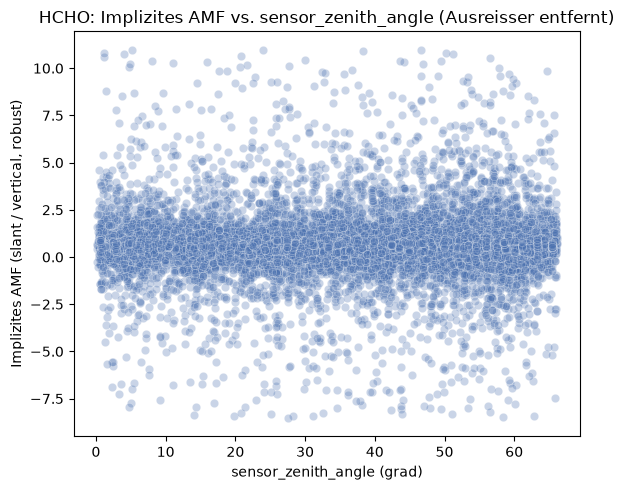


=== SO2 ===
Ausreisser ausserhalb 1.-99. Perzentil: 460 von 22990 (2.0%)
Implizites AMF (robust): mean=0.398, median=0.344, std=0.303
Offizielles AMF: mean=0.429, median=0.378, std=0.252
Korrelation mit implizitem AMF (robuste Teilmenge):
official_amf           0.745349
solar_zenith_angle    -0.362668
sensor_zenith_angle   -0.053488
Name: implied_amf, dtype: float64


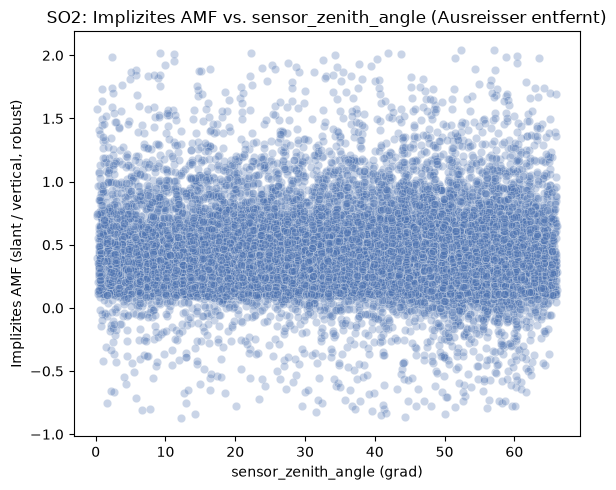

In [76]:
# Empirischer Test: "Implizites AMF" (slant / vertical) vs. Sensor-/Sonnenwinkel
# -> prueft, ob AMF-Korrektur wirklich wirkt, oder ob AMF ohnehin ~1 ist (Satellit nahezu senkrecht)
#
# Wichtig: slant/vertical ist ein roher Quotient zweier verrauschter Messgroessen.
# Liegt der Nenner (vertical) nahe 0 (Hintergrundregionen, wenig Schadstoff), "explodiert"
# der Quotient auf absurd grosse/negative Werte. Deshalb robust auf 1.-99. Perzentil clippen,
# BEVOR Mittelwert/Std/Korrelation berechnet werden (nicht nur fuers Plotten!).

amf_pairs = {
    "NO2": {
        "slant": "L3_NO2_NO2_slant_column_number_density",
        "vertical": "L3_NO2_NO2_column_number_density",
        "official_amf": None,
        "sensor_angle": "L3_NO2_sensor_zenith_angle",
        "solar_angle": "L3_NO2_solar_zenith_angle",
    },
    "HCHO": {
        "slant": "L3_HCHO_HCHO_slant_column_number_density",
        "vertical": "L3_HCHO_tropospheric_HCHO_column_number_density",
        "official_amf": "L3_HCHO_tropospheric_HCHO_column_number_density_amf",
        "sensor_angle": "L3_HCHO_sensor_zenith_angle",
        "solar_angle": "L3_HCHO_solar_zenith_angle",
    },
    "SO2": {
        "slant": "L3_SO2_SO2_slant_column_number_density",
        "vertical": "L3_SO2_SO2_column_number_density",
        "official_amf": "L3_SO2_SO2_column_number_density_amf",
        "sensor_angle": "L3_SO2_sensor_zenith_angle",
        "solar_angle": "L3_SO2_solar_zenith_angle",
    },
}

for gas, cols in amf_pairs.items():
    slant = df_train[cols["slant"]]
    vertical = df_train[cols["vertical"]]

    implied_amf = (slant / vertical.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)

    # robust: Ausreisser durch Divisionen nahe 0 entfernen (1.-99. Perzentil)
    lower, upper = implied_amf.quantile([0.01, 0.99])
    mask = implied_amf.between(lower, upper)
    implied_amf_robust = implied_amf[mask]

    n_total = implied_amf.notna().sum()
    n_outlier = n_total - mask.sum()

    print(f"\n=== {gas} ===")
    print(f"Ausreisser ausserhalb 1.-99. Perzentil: {n_outlier} von {n_total} ({n_outlier/n_total:.1%})")
    print(
        f"Implizites AMF (robust): mean={implied_amf_robust.mean():.3f}, "
        f"median={implied_amf_robust.median():.3f}, std={implied_amf_robust.std():.3f}"
    )

    check_df = pd.DataFrame({
        "implied_amf": implied_amf,
        "sensor_zenith_angle": df_train[cols["sensor_angle"]],
        "solar_zenith_angle": df_train[cols["solar_angle"]],
    })[mask]  # nur robuste Teilmenge fuer Korrelation nutzen

    if cols["official_amf"] is not None:
        official_amf = df_train[cols["official_amf"]]
        check_df["official_amf"] = official_amf[mask]
        print(
            f"Offizielles AMF: mean={official_amf.mean():.3f}, "
            f"median={official_amf.median():.3f}, std={official_amf.std():.3f}"
        )

    print("Korrelation mit implizitem AMF (robuste Teilmenge):")
    print(check_df.corr()["implied_amf"].drop("implied_amf").sort_values(key=abs, ascending=False))

    plt.figure(figsize=(6, 5))
    sns.scatterplot(data=check_df, x="sensor_zenith_angle", y="implied_amf", alpha=0.3, color="#4C72B0")
    plt.xlabel("sensor_zenith_angle (grad)")
    plt.ylabel("Implizites AMF (slant / vertical, robust)")
    plt.title(f"{gas}: Implizites AMF vs. sensor_zenith_angle (Ausreisser entfernt)")
    plt.tight_layout()
    plt.show()


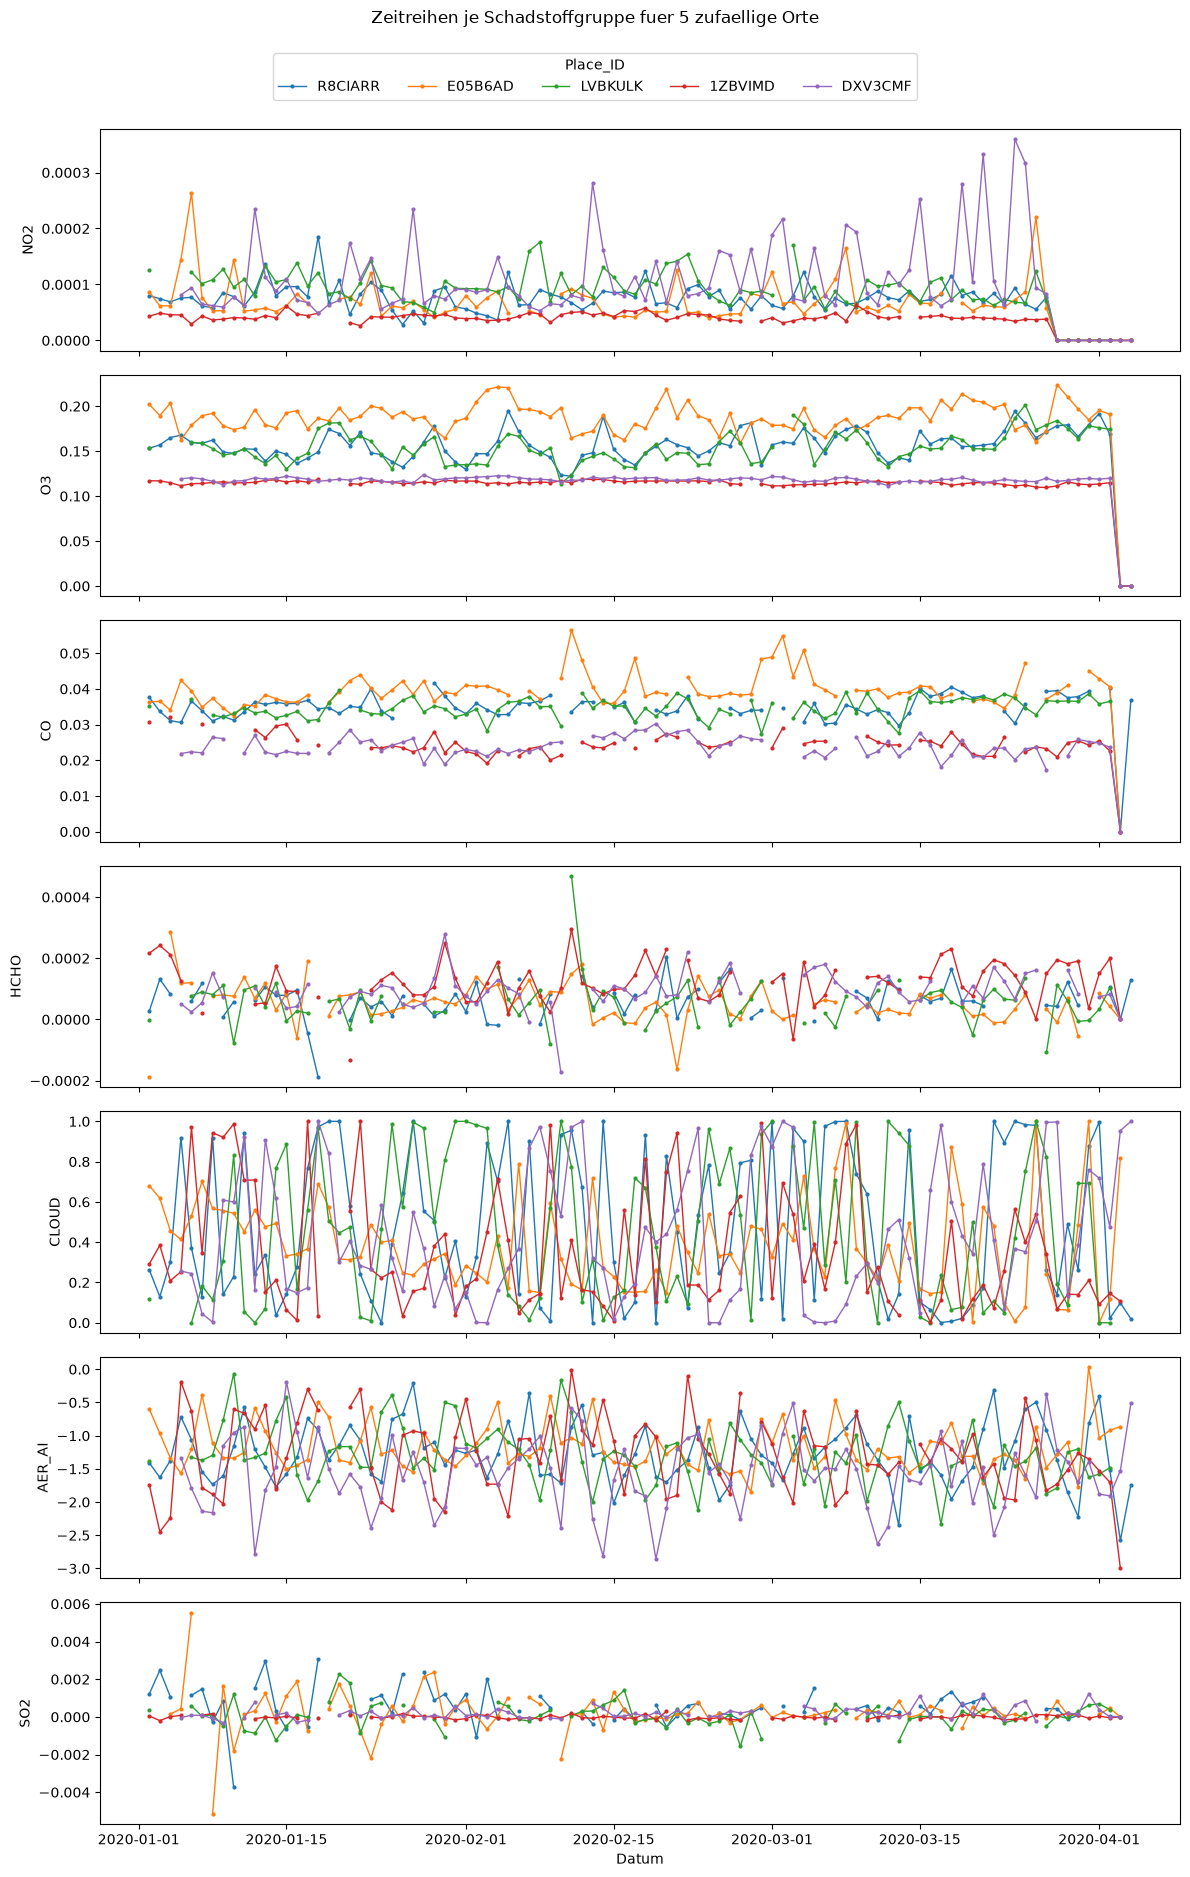

In [91]:
# Zeitreihen je Schadstoffgruppe fuer 5 zufaellige Orte, um Luecken-Groesse fuer Interpolation zu beurteilen
# -> ein Messwert pro Gruppe, auf durchgehenden Tagesindex reindexiert, damit Luecken als
#    Unterbrechungen der Linie sichtbar bleiben (nicht ueberbrueckt werden)

gas_repr_cols = {
    "NO2": "L3_NO2_NO2_column_number_density",
    "O3": "L3_O3_O3_column_number_density",
    "CO": "L3_CO_CO_column_number_density",
    "HCHO": "L3_HCHO_tropospheric_HCHO_column_number_density",
    "CLOUD": "L3_CLOUD_cloud_fraction",
    "AER_AI": "L3_AER_AI_absorbing_aerosol_index",
    "SO2": "L3_SO2_SO2_column_number_density",
}

# 5 zufaellige Orte auswaehlen (fester Seed fuer Reproduzierbarkeit)
rng = np.random.default_rng(42)
size = 5
random_places = rng.choice(df_train["Place_ID"].unique(), size, replace=False)

palette = sns.color_palette("tab10", n_colors=len(random_places))
place_colors = dict(zip(random_places, palette))

fig, axes = plt.subplots(len(gas_repr_cols), 1, figsize=(12, 18), sharex=True)

for ax, (gas, col) in zip(axes, gas_repr_cols.items()):
    for place_id in random_places:
        df_place = df_train[df_train["Place_ID"] == place_id].set_index("Date").sort_index()
        full_range = pd.date_range(df_place.index.min(), df_place.index.max(), freq="D")
        df_place = df_place.reindex(full_range)
        ax.plot(
            df_place.index, df_place[col],
            marker="o", markersize=2, linewidth=1,
            color=place_colors[place_id], label=place_id,
        )
    ax.set_ylabel(gas)

axes[-1].set_xlabel("Datum")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Place_ID", loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=5)
fig.suptitle("Zeitreihen je Schadstoffgruppe fuer " + str(size)+ " zufaellige Orte", y=1.04)
plt.tight_layout()
plt.show()


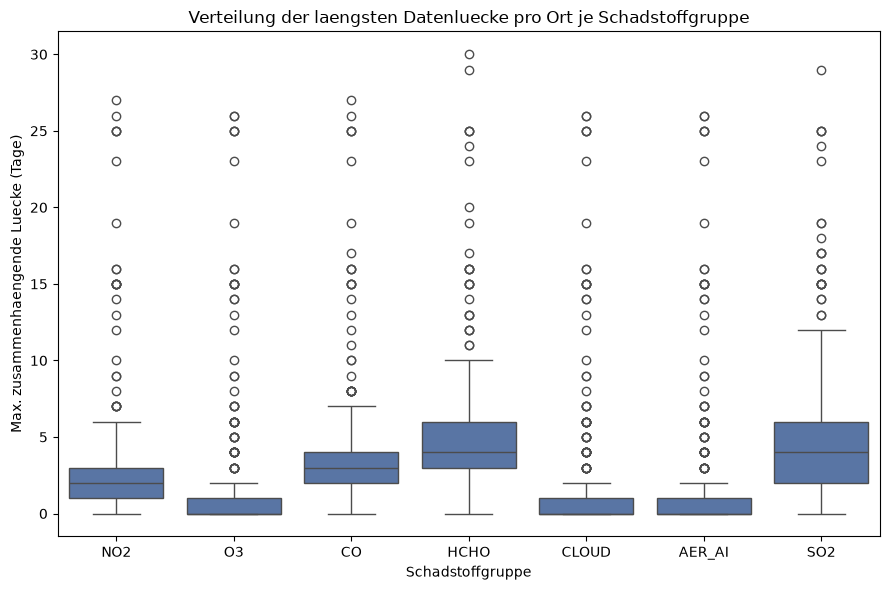

        count      mean       std  min  25%  50%  75%   max
gas                                                        
AER_AI  340.0  1.767647  4.434593  0.0  0.0  0.0  1.0  26.0
CLOUD   340.0  1.791176  4.429112  0.0  0.0  0.0  1.0  26.0
CO      340.0  3.929412  4.050677  0.0  2.0  3.0  4.0  27.0
HCHO    339.0  5.079646  4.512589  0.0  3.0  4.0  6.0  30.0
NO2     339.0  2.952802  4.218600  0.0  1.0  2.0  3.0  27.0
O3      340.0  1.932353  4.387379  0.0  0.0  0.0  1.0  26.0
SO2     339.0  5.041298  4.553892  0.0  2.0  4.0  6.0  29.0


In [83]:
# Quantitative Einschaetzung: maximale zusammenhaengende Luecke (Tage) je Ort und Schadstoffgruppe
# (nur Luecken ZWISCHEN zwei vorhandenen Messungen, keine Rand-Luecken vor der ersten/nach der letzten)

def max_gap_days(group, col):
    s = group[col].dropna()
    if len(s) < 2:
        return np.nan
    full_idx = pd.date_range(s.index.min(), s.index.max(), freq="D")
    s_full = group[col].reindex(full_idx)
    is_na = s_full.isna()
    gap_id = (~is_na).cumsum()
    gap_lengths = is_na.groupby(gap_id).sum()
    return gap_lengths.max()

df_indexed = df_train.set_index("Date")
gap_records = []
for gas, col in gas_repr_cols.items():
    for place_id, group in df_indexed.groupby("Place_ID"):
        gap_records.append({"gas": gas, "place_id": place_id, "max_gap_days": max_gap_days(group, col)})

gap_df = pd.DataFrame(gap_records)

plt.figure(figsize=(9, 6))
sns.boxplot(data=gap_df, x="gas", y="max_gap_days", color="#4C72B0", order=list(gas_repr_cols.keys()))
plt.ylabel("Max. zusammenhaengende Luecke (Tage)")
plt.xlabel("Schadstoffgruppe")
plt.title("Verteilung der laengsten Datenluecke pro Ort je Schadstoffgruppe")
plt.tight_layout()
plt.show()

print(gap_df.groupby("gas")["max_gap_days"].describe())


## Erkenntnisse: Datenluecken je Schadstoffgruppe (Interpolation sinnvoll?)

- **CLOUD, AER_AI, O3** haben sehr kurze typische Luecken (Median 0 Tage, 75%-Quantil <= 1 Tag) -> lineare Interpolation zwischen Zeitpunkten fuer einen festen Ort ist hier unproblematisch.
- **NO2** liegt dazwischen (Median 2 Tage, 75%-Quantil 3 Tage) -> Interpolation mit kleinem Limit (z.B. max. 3-5 Tage) sinnvoll.
- **CO, HCHO, SO2** haben die groessten typischen Luecken (Median 3-4 Tage, 75%-Quantil 4-6 Tage) -> Interpolation nur mit begrenztem Limit verwenden, nicht unbegrenzt durchfuehren.
- **Alle Gruppen haben eine lange Ausreisser-Spitze bis 23-30 Tage** (sichtbar als viele Ausreisser-Punkte im Boxplot) -> fuer die Orte/Zeitraeume mit solch langen Luecken ist Interpolation NICHT sinnvoll (zu grosse Unsicherheit); hier eher auf ortsbasierten Median/eine andere Strategie zurueckfallen.
- Zusaetzlich aufgefallen (siehe Zeitreihen-Plot fuer den Ort mit den wenigsten NaNs): bei einigen Gruppen (z.B. NO2, O3, CO) gibt es Ende Maerz einen Block mit Werten nahe **0 statt NaN** - moeglicher Daten-Qualitaetsartefakt (Sensorausfall als 0 statt als fehlender Wert kodiert), sollte separat geprueft werden, bevor interpoliert/imputiert wird.

### Empfehlung fuer die Imputationsstrategie
- [ ] Zeitliche Interpolation (`interpolate()`) pro Ort NUR mit einem Limit verwenden (z.B. `limit=3` bis `limit=5` Tage, je nach Gasgruppe), NICHT unbegrenzt.
- [ ] Fuer Luecken, die das Limit ueberschreiten, auf ortsbasierten Median/Mittelwert zurueckfallen (Kombination aus Interpolation + Median-Imputation, nicht entweder/oder).
- [ ] Verdaechtige 0-Werte (statt NaN) bei NO2/O3/CO um Ende Maerz stichprobenartig pruefen, bevor sie als echte Messwerte interpretiert werden.


## Top-Features fuer lineare Regression: Scatterplots gegen target (roh vs. log1p)

Kandidaten (hoechste Korrelation mit `target`): `wind_speed`, HCHO-, CO- und NO2-Column-Density. Fuer ein einfaches lineares Regressions-Baseline (ohne Regularisierung) ist Skalierung irrelevant, aber eine Log-Transformation der schiefen Dichte-Spalten kann die Linearitaets-Annahme besser erfuellen. Die Scatterplots unten vergleichen roh vs. `log1p`-transformiert je Feature (inkl. Pearson-r und linearer Regressionsgerade), um das visuell/quantitativ zu pruefen.


In [ ]:
# Scatterplots: Top-Features (roh vs. echter Log-Transform) gegen target, um Linearitaet zu pruefen
#
# WICHTIG 1: log1p(x) = ln(1+x) ist fuer sehr kleine x (hier: Dichte-Spalten im Bereich 1e-5 bis 1e-3)
# praktisch ein No-Op (Taylor-Naeherung ln(1+x) ~ x fuer x << 1) - deshalb echter log(x) ohne "+1"-Offset.
#
# WICHTIG 2: HCHO/CO/NO2 enthalten bekannte Sensorausfaelle (exakte 0, siehe 05_data_cleaning_and_modeling),
# bei NO2 betrifft das ~9% der Zeilen. Ein reiner Floor-Clip wuerde all diese Ausfall-Zeilen auf denselben
# Floor-Wert ziehen und so eine kuenstliche Punktwand im Log-Plot erzeugen, die Korrelation/Linearitaet
# verzerrt. Deshalb werden diese Zeilen hier (nur fuer die Gasspalten, nicht fuer wind_speed) vorher
# komplett entfernt statt geclippt.
from scipy.stats import pearsonr

gas_cols = {
    "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_CO_CO_column_number_density",
    "L3_NO2_NO2_column_number_density",
}
top_features = {
    "wind_speed": "Wind (abs. Windgeschwindigkeit)",
    "L3_HCHO_tropospheric_HCHO_column_number_density": "HCHO column density",
    "L3_CO_CO_column_number_density": "CO column density",
    "L3_NO2_NO2_column_number_density": "NO2 column density",
}

fig, axes = plt.subplots(len(top_features), 2, figsize=(12, 4 * len(top_features)))

for row, (col, label) in enumerate(top_features.items()):
    data = df_train[[col, "target"]].dropna().copy()
    if col in gas_cols:
        n_before = len(data)
        data = data[data[col] != 0]
        print(f"{label}: {n_before - len(data)} Sensorausfall-Zeilen (exakte 0) entfernt")

    positive = data[col][data[col] > 0]
    floor = positive.quantile(0.01)
    data["log_feature"] = np.log(data[col].clip(lower=floor))

    for ax_col, (x_col, x_label) in enumerate([(col, label), ("log_feature", f"log({label})")]):
        ax = axes[row, ax_col]
        r, _ = pearsonr(data[x_col], data["target"])
        sns.regplot(
            data=data, x=x_col, y="target", ax=ax,
            scatter_kws={"alpha": 0.15, "s": 8, "color": "#4C72B0"},
            line_kws={"color": "#C44E52"},
        )
        ax.set_xlabel(x_label)
        ax.set_ylabel("target")
        ax.set_title(f"r = {r:.3f}", fontsize=10)

fig.suptitle("Top-Features vs. target: roh vs. log-transformiert (ohne Sensorausfaelle)", y=1.01)
plt.tight_layout()
plt.show()
